# 1. Business Problem & Objective

## Business Objective

Build a machine learning regression model that estimates the
listing price of a used car from its available attributes, such as
brand, model, year, mileage, fuel type and vehicle condition.

The dataset will be inspected before modelling to confirm its
target variable, currency, feature definitions and data quality.

## Business Use Case

The estimator could help:
- Sellers establish a reasonable initial asking price.
- Buyers compare listed prices with model-estimated prices.
- A used-car marketplace provide an indicative price estimate.

## Machine Learning Problem

This is a **supervised regression problem**.

- **Input (X):** Vehicle-related features.
- **Target (y):** The vehicle's listed selling price, subject to confirmation of the dataset's column names and units.
- **Output:** A continuous numerical price estimate.

## Scope and Limitations

The model estimates a listing price, not necessarily the final transaction price. It will not claim to estimate battery health or battery degradation unless reliable battery-health data is available.

# 2. Success Criteria & Evaluation Metrics

The model will be evaluated using the following regression metrics.

## 1. Mean Absolute Error (MAE) — Primary Metric

MAE measures the average absolute difference between actual and predicted prices.

- Lower MAE is better.
- It is easy to interpret in the same units as the target price.

## 2. Root Mean Squared Error (RMSE)

RMSE penalizes larger prediction errors more heavily than MAE.

- Lower RMSE is better.
- It helps identify whether some predictions have particularly large errors.

## 3. R-squared (R²)

R² measures how much variation in the target price is explained by the model, relative to predicting the mean price.

- Higher is generally better.
- R² can be negative if the model performs worse than the mean-prediction baseline.

## Model Selection Criteria

- Use MAE as the primary metric for comparing models.
- Use RMSE to assess the impact of large errors.
- Use R² as a secondary measure of model fit.
- Compare candidate models using the same validation strategy.
- Evaluate the selected model on the held-out test set only after model selection is complete.

A numerical MAE target will be defined after inspecting the target-price distribution and units. No performance threshold will be assumed before understanding the dataset.

# 3. Imports & Environment Setup

This section imports the libraries required for data analysis and visualization
and checks the Python environment used by the notebook.

- Pandas and NumPy: data manipulation and numerical operations.
- Matplotlib and Seaborn: exploratory data visualization.
- pathlib: portable file and folder paths.
- sys and platform: environment information and debugging.

In [3]:
import sys
import platform
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display environment information
print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Operating system:", platform.system())

print("\nLibrary versions:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

Python version: 3.13.9
Python executable: C:\Users\SUBHAM\anaconda3\python.exe
Operating system: Windows

Library versions:
Pandas: 2.3.3
NumPy: 2.3.4
Matplotlib: 3.10.7
Seaborn: 0.13.2


In [4]:
# Notebook is expected to be inside the notebook/ folder
PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name.lower() == "notebook"
    else Path.cwd()
)

DATA_PATH = PROJECT_DIR / "data" / "used_cars.csv"

print("Project folder:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Project folder: D:\SAURABH\FDE_Course\Projects\Used_Car_Price_Prediction
Dataset path: D:\SAURABH\FDE_Course\Projects\Used_Car_Price_Prediction\data\used_cars.csv
Dataset exists: True


# 4. Data Loading

Load the source CSV into a Pandas DataFrame.

Before performing any cleaning or transformation, verify that the file exists
and inspect a small sample of the raw data.

The original dataset will remain unchanged during initial inspection.

In [5]:
# Verify that the dataset exists
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at: {DATA_PATH}")

# Load the raw dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully.
Number of rows: 4009
Number of columns: 12


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

Column names:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


# 5. Data Quality Checks

This section examines missing values, duplicate records, categorical inconsistencies, and the formats of numerical fields before data cleaning.

The price and milage columns currently contain text-formatted values. We will inspect their formats before converting them into numeric values.

No records will be removed or modified during this initial assessment.

In [7]:
# 1. Missing values
print("Missing values per column:")
print(df.isnull().sum())

# 2. Exact duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Unique values in important categorical columns
for col in ["fuel_type", "accident", "clean_title"]:
    print(f"\n{col} — unique values:")
    print(df[col].value_counts(dropna=False))

# 4. Inspect raw price and mileage formats
print("\nSample prices:")
print(df["price"].head(10).tolist())

print("\nSample mileage values:")
print(df["milage"].head(10).tolist())

# 5. Model year range
print("\nModel year range:")
print(df["model_year"].min(), "to", df["model_year"].max())

Missing values per column:
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

Duplicate rows: 0

fuel_type — unique values:
fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

accident — unique values:
accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

clean_title — unique values:
clean_title
Yes    3413
NaN     596
Name: count, dtype: int64

Sample prices:
['$10,300', '$38,005', '$54,598', '$15,500', '$34,999', '$14,798', '$31,000', '$7,300', '$41,927', '$69,950']

Sample mileage values:
['51,000

# 6. Data Understanding

This section examines numerical distributions, categorical feature frequencies, and potential data-quality issues before preprocessing.

The goal is to understand the dataset and identify unusual values without modifying the original data.

In [8]:
# 1. Dataset summary
display(df.describe(include="all").T)

# 2. Check categorical feature frequencies
categorical_cols = [
    "brand", "fuel_type", "transmission",
    "accident", "clean_title"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))

# 3. Inspect extreme model years
print("\nOldest cars:")
display(df.nsmallest(10, "model_year")[["brand", "model", "model_year", "price"]])

print("\nNewest cars:")
display(df.nlargest(10, "model_year")[["brand", "model", "model_year", "price"]])

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,4009,57,Ford,386,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,4009,1898,M3 Base,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model_year,4009.0,NaN,NaN,NaN,2015.51559,6.104816,1974.0,2012.0,2017.0,2020.0,2024.0
milage,4009,2818,"110,000 mi.",16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel_type,3839,7,Gasoline,3309,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,4009,1146,2.0L I4 16V GDI DOHC Turbo,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4009,62,A/T,1037,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ext_col,4009,319,Black,905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
int_col,4009,156,Black,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
accident,3896,2,None reported,2910,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- brand ---
brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land             130
Nissan           116
Cadillac         107
GMC               91
RAM               91
Dodge             90
Name: count, dtype: int64

--- fuel_type ---
fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

--- transmission ---
transmission
A/T                               1037
8-Speed A/T                        406
Transmission w/Dual Shift Mode     398
6-Speed A/T                        362
6-Speed M/T                        248
Automatic                          237
7-Speed A/T                        209
8-Speed Automatic                  176
10-Speed A/T                       119
5-Speed A/T  

,brand,model,model_year,price
855,Ford,Bronco,1974,"$115,000"
1088,Mazda,MX-5 Miata Base,1992,"$11,500"
257,Toyota,Land Cruiser Base,1993,"$29,500"
692,Honda,Civic EX,1993,"$9,599"
1134,Mercedes-Benz,E-Class 400E,1993,"$15,300"
1746,Nissan,300ZX Base,1993,"$7,000"
1805,Mercury,Capri XR2,1993,"$4,200"
2026,Mercedes-Benz,E-Class D 2.5 Turbo,1993,"$22,500"
2303,Acura,NSX Base,1993,"$90,200"
3469,Ford,F-250 XL SuperCab H/D,1993,"$21,900"



Newest cars:


,brand,model,model_year,price
443,BMW,M3 CS,2024,"$128,995"
556,Mazda,CX-90 Premium,2024,"$52,991"
1691,BMW,M3 CS,2024,"$145,000"
2289,BMW,840 i xDrive,2024,"$90,000"
3309,GMC,Sierra 2500 Denali,2024,"$81,500"
3529,Lexus,NX 350h Premium,2024,"$50,999"
20,Genesis,GV70 3.5T Sport,2023,"$60,000"
23,Ford,F-150 XLT,2023,"$58,504"
41,Honda,Passport Elite,2023,"$45,498"
56,Nissan,Rogue SV,2023,"$30,999"


# 7. Numeric Data Cleaning

Convert price and milage from formatted text to numeric values. Preserve the original dataset and verify that the conversion introduces no unexpected missing values.

In [9]:
# Create a working copy; preserve the original df
df_clean = df.copy()

# Convert price and mileage to numeric
df_clean["price"] = (
    df_clean["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

df_clean["milage"] = (
    df_clean["milage"]
    .str.replace(" mi.", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Verify conversions
print(df_clean[["price", "milage"]].dtypes)
display(df_clean[["price", "milage"]].describe())

print("Missing values after conversion:")
print(df_clean[["price", "milage"]].isnull().sum())

price     float64
milage    float64
dtype: object


,price,milage
count,4.009000e+03,4009.000000
mean,4.455319e+04,64717.551010
std,7.871064e+04,52296.599459
min,2.000000e+03,100.000000
25%,1.720000e+04,23044.000000
50%,3.100000e+04,52775.000000
75%,4.999000e+04,94100.000000
max,2.954083e+06,405000.000000


Missing values after conversion:
price     0
milage    0
dtype: int64


## 8. Outlier Inspection

Inspect the highest-priced and highest-mileage vehicles to determine whether extreme values are plausible or potential data-quality issues. Outliers will not be removed solely because they are extreme.

Top 10 prices:


,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000.0,2954083.0
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330.0,1950995.0
3046,Porsche,Carrera GT Base,2005,4400.0,1599000.0
1356,Lamborghini,Aventador SVJ Base,2021,6987.0,749950.0
624,Rolls-Royce,Cullinan,2022,398.0,695000.0
979,Lamborghini,Aventador SVJ Base,2019,6929.0,649999.0
1615,Rolls-Royce,Phantom,2023,1560.0,599995.0
1508,Rolls-Royce,Phantom,2018,7585.0,599000.0
3655,Lamborghini,Aventador S Base,2018,5858.0,491836.0
1061,Dodge,Viper GTC,2017,1389.0,489995.0


Top 10 mileage values:


,brand,model,model_year,milage,price
2764,Honda,Accord Sport,2013,405000.0,6000.0
3348,Mercedes-Benz,Sprinter 2500,2016,399000.0,24500.0
2175,Ford,Excursion Limited,2001,333361.0,17000.0
3757,Ford,F-250 XL Crew Cab Super Duty,2004,315000.0,9200.0
31,Dodge,Ram 1500 Laramie Mega Cab,2006,300183.0,10900.0
1145,GMC,Sierra 3500 SLE,2002,300000.0,5000.0
3118,Dodge,Dakota Sport,1997,285000.0,6399.0
3747,Ford,F-150 Lariat SuperCrew,2004,271000.0,9500.0
2558,Toyota,Land Cruiser Base,2010,269885.0,22500.0
3158,Toyota,4Runner 4WD,1999,267000.0,8000.0


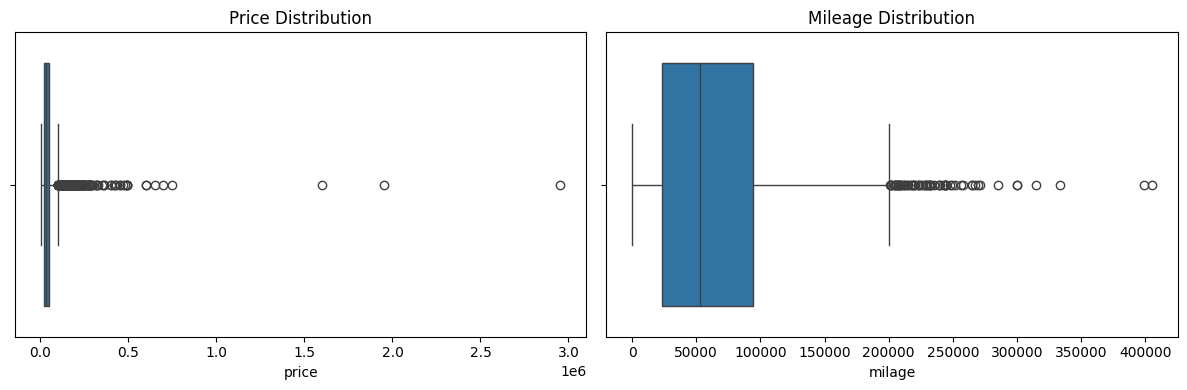

In [10]:
# Highest-priced vehicles
print("Top 10 prices:")
display(
    df_clean.nlargest(10, "price")[
        ["brand", "model", "model_year", "milage", "price"]
    ]
)

# Highest-mileage vehicles
print("Top 10 mileage values:")
display(
    df_clean.nlargest(10, "milage")[
        ["brand", "model", "model_year", "milage", "price"]
    ]
)

# Visualize distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df_clean["price"], ax=axes[0])
axes[0].set_title("Price Distribution")

sns.boxplot(x=df_clean["milage"], ax=axes[1])
axes[1].set_title("Mileage Distribution")

plt.tight_layout()
plt.show()

## 9. Investigating Extreme Prices

Inspect vehicles priced above $200,000 and examine price percentiles to understand the target distribution. Extreme prices may represent genuine luxury vehicles or potential data-quality issues.

We will investigate unusual records before deciding whether to exclude them. No records are removed at this stage.S

In [11]:
# Inspect cars priced above $200,000
high_price_cars = df_clean[df_clean["price"] > 200_000]

display(
    high_price_cars[
        ["brand", "model", "model_year", "milage", "price"]
    ].sort_values("price", ascending=False)
)

print("Cars above $200,000:", len(high_price_cars))

# Check price distribution using percentiles
print("\nPrice percentiles:")
print(df_clean["price"].quantile([0.90, 0.95, 0.99, 0.995, 1.00]))

,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000.0,2954083.0
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330.0,1950995.0
3046,Porsche,Carrera GT Base,2005,4400.0,1599000.0
1356,Lamborghini,Aventador SVJ Base,2021,6987.0,749950.0
624,Rolls-Royce,Cullinan,2022,398.0,695000.0
...,...,...,...,...,...
2957,Lamborghini,Huracan LP580-2,2017,14586.0,209991.0
1514,Lamborghini,Urus Base,2019,16876.0,209900.0
3091,Porsche,911 GT3,2018,5989.0,209000.0
3433,Porsche,911 Turbo,2021,11938.0,209000.0


Cars above $200,000: 75

Price percentiles:
0.900      79999.00
0.950     111600.00
0.990     272713.28
0.995     398303.64
1.000    2954083.00
Name: price, dtype: float64


## 10. Target Transformation

Compare the original price distribution with its log-transformed version to assess the impact of extreme values and right-skewness. The results will help determine whether target transformation should be evaluated during model training.

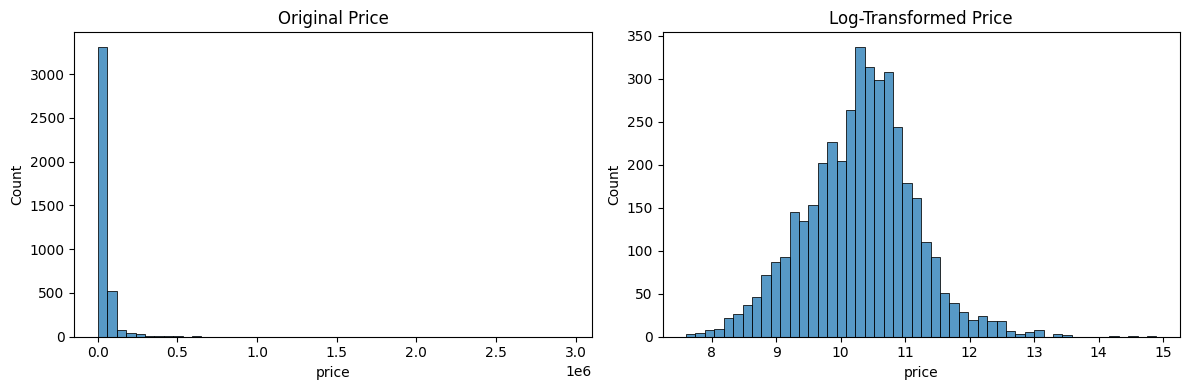

Price skewness: 19.51
Log-price skewness: 0.11


In [12]:
# Compare original and log-transformed prices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean["price"], bins=50, ax=axes[0])
axes[0].set_title("Original Price")

sns.histplot(np.log1p(df_clean["price"]), bins=50, ax=axes[1])
axes[1].set_title("Log-Transformed Price")

plt.tight_layout()
plt.show()

print("Price skewness:", round(df_clean["price"].skew(), 2))
print("Log-price skewness:", round(np.log1p(df_clean["price"]).skew(), 2))

## 11. Categorical Data Cleaning

Standardize invalid or unknown labels in `fuel_type` and inspect the remaining categorical values. Missing values will be handled later through a preprocessing pipeline to prevent data leakage.

In [13]:
# Standardize invalid fuel-type labels as missing
df_clean["fuel_type"] = df_clean["fuel_type"].replace(
    ["–", "not supported"], np.nan
)

# Check categorical values after standardization
for col in ["fuel_type", "accident", "clean_title"]:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False))

# Check missing values
print("\nMissing values:")
print(df_clean.isnull().sum())


--- fuel_type ---
fuel_type
Gasoline          3309
NaN                217
Hybrid             194
E85 Flex Fuel      139
Diesel             116
Plug-In Hybrid      34
Name: count, dtype: int64

--- accident ---
accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

--- clean_title ---
clean_title
Yes    3413
NaN     596
Name: count, dtype: int64

Missing values:
brand             0
model             0
model_year        0
milage            0
fuel_type       217
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


## 12. Feature Engineering

Create `vehicle_age` from the model year to represent the vehicle's age. Retain `model_year` for now so we can compare its usefulness during model development.

The reference year is fixed for this initial analysis and will be made configurable in the final prediction application.

In [14]:
# Create vehicle age using the current reference year
REFERENCE_YEAR = 2026

df_clean["vehicle_age"] = REFERENCE_YEAR - df_clean["model_year"]

# Inspect the engineered feature
display(
    df_clean[
        ["model_year", "vehicle_age", "milage", "price"]
    ].head(10)
)

print("\nVehicle age summary:")
print(df_clean["vehicle_age"].describe())

print("\nNegative vehicle ages:", (df_clean["vehicle_age"] < 0).sum())

,model_year,vehicle_age,milage,price
0,2013,13,51000.0,10300.0
1,2021,5,34742.0,38005.0
2,2022,4,22372.0,54598.0
3,2015,11,88900.0,15500.0
4,2021,5,9835.0,34999.0
5,2016,10,136397.0,14798.0
6,2017,9,84000.0,31000.0
7,2001,25,242000.0,7300.0
8,2021,5,23436.0,41927.0
9,2020,6,34000.0,69950.0



Vehicle age summary:
count    4009.000000
mean       10.484410
std         6.104816
min         2.000000
25%         6.000000
50%         9.000000
75%        14.000000
max        52.000000
Name: vehicle_age, dtype: float64

Negative vehicle ages: 0


## 13. Feature Relationship Analysis

Examine the relationship between vehicle price, mileage, and age. Correlation provides an initial view of linear relationships, but it does not establish causation or capture every relationship in the data.

Correlation matrix:


,price,milage,vehicle_age
price,1.00,-0.31,-0.20
milage,-0.31,1.00,0.62
vehicle_age,-0.20,0.62,1.00


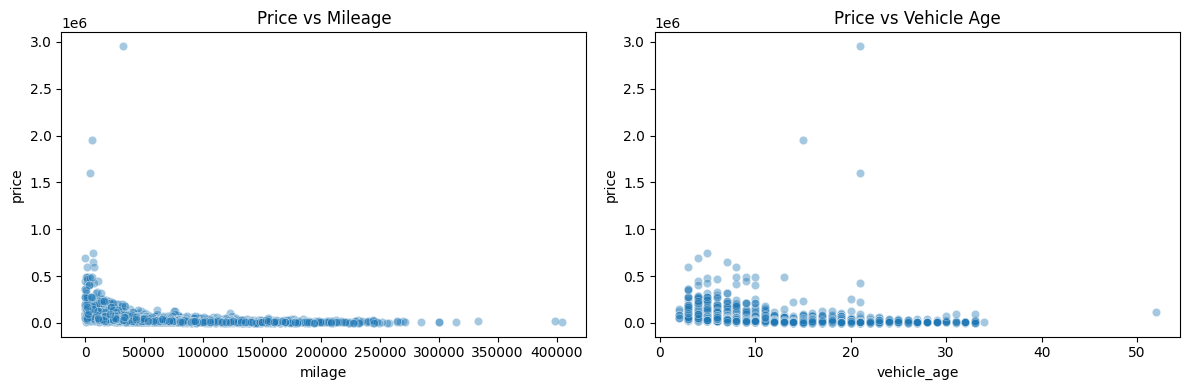

In [15]:
# Correlation between numerical features
numeric_cols = ["price", "milage", "vehicle_age"]

print("Correlation matrix:")
display(df_clean[numeric_cols].corr().round(2))

# Visualize relationships
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(
    data=df_clean, x="milage", y="price",
    alpha=0.4, ax=axes[0]
)
axes[0].set_title("Price vs Mileage")

sns.scatterplot(
    data=df_clean, x="vehicle_age", y="price",
    alpha=0.4, ax=axes[1]
)
axes[1].set_title("Price vs Vehicle Age")

plt.tight_layout()
plt.show()

## 14. Categorical Feature Analysis

Explore how prices vary across vehicle brands, fuel types, and accident-history categories. These comparisons help identify potentially useful predictors while accounting for the influence of expensive vehicles.

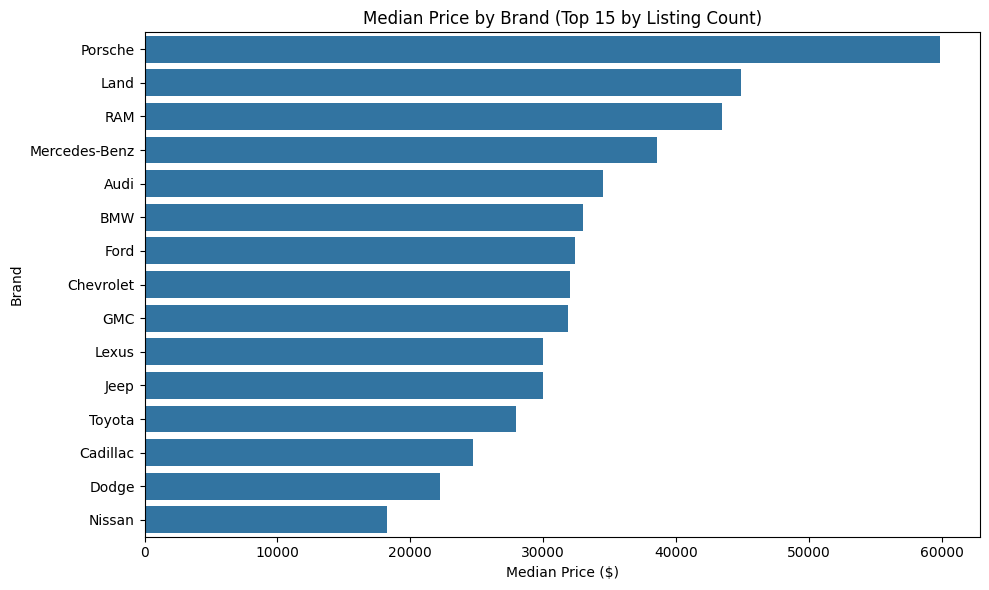

,count,median
fuel_type,,
Hybrid,194,45499.0
Diesel,116,45450.0
Plug-In Hybrid,34,44945.0
NaN,217,43000.0
Gasoline,3309,29950.0
E85 Flex Fuel,139,19500.0


,count,median
accident,,
At least 1 accident or damage reported,986,20900.0
None reported,2910,35667.5
NaN,113,36500.0


In [16]:
# Median price by brand (top 15 brands by number of listings)
top_brands = df_clean["brand"].value_counts().head(15).index

brand_prices = (
    df_clean[df_clean["brand"].isin(top_brands)]
    .groupby("brand")["price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=brand_prices.values, y=brand_prices.index)
plt.title("Median Price by Brand (Top 15 by Listing Count)")
plt.xlabel("Median Price ($)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

# Median price by fuel type
display(
    df_clean.groupby("fuel_type", dropna=False)["price"]
    .agg(["count", "median"])
    .sort_values("median", ascending=False)
)

# Median price by accident history
display(
    df_clean.groupby("accident", dropna=False)["price"]
    .agg(["count", "median"])
)

## 15. Define Features and Target

Set `price` as the regression target and use the remaining vehicle attributes as predictors. Retain relevant categorical features and the engineered `vehicle_age` feature.

Preprocessing and missing-value handling will be fitted only on training data through a pipeline.

In [17]:
# Define target
TARGET = "price"

# Keep model_year for comparison; vehicle_age is also included for now
FEATURES = [
    "brand",
    "model",
    "model_year",
    "vehicle_age",
    "milage",
    "fuel_type",
    "engine",
    "transmission",
    "ext_col",
    "int_col",
    "accident",
    "clean_title",
]

X = df_clean[FEATURES].copy()
y = df_clean[TARGET].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget summary:")
print(y.describe())

print("\nMissing values in features:")
print(X.isnull().sum())

Feature matrix shape: (4009, 12)
Target shape: (4009,)

Target summary:
count    4.009000e+03
mean     4.455319e+04
std      7.871064e+04
min      2.000000e+03
25%      1.720000e+04
50%      3.100000e+04
75%      4.999000e+04
max      2.954083e+06
Name: price, dtype: float64

Missing values in features:
brand             0
model             0
model_year        0
vehicle_age       0
milage            0
fuel_type       217
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
dtype: int64


## 16. Train/Test Split

Split the dataset into training (80%) and testing (20%) sets before model preprocessing. The test set will remain untouched until final evaluation.

Use a fixed random state to make results reproducible.

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (3207, 12)
Testing features: (802, 12)
Training target: (3207,)
Testing target: (802,)


## 17. Preprocessing Pipeline

Separate numerical and categorical features. Impute missing numerical values using the median, fill missing categorical values with `Unknown`, and one-hot encode categorical variables.

All preprocessing steps will be fitted only on training data to prevent data leakage. We will retain the original feature values and avoid removing outliers at this stage.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate feature types
numeric_features = [
    "model_year",
    "vehicle_age",
    "milage",
]

categorical_features = [
    "brand",
    "model",
    "fuel_type",
    "engine",
    "transmission",
    "ext_col",
    "int_col",
    "accident",
    "clean_title",
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 18. Baseline Model

Train a Dummy Regressor that predicts the median price from the training set for every observation. Evaluate it on the held-out test set using MAE, RMSE, and R².

This baseline establishes a minimum performance benchmark before training more complex models.

In [20]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline model
baseline_model = DummyRegressor(strategy="median")

baseline_model.fit(X_train, y_train)

# Predict on test data
baseline_preds = baseline_model.predict(X_test)

# Evaluate
baseline_mae = mean_absolute_error(y_test, baseline_preds)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_preds))
baseline_r2 = r2_score(y_test, baseline_preds)

print("Baseline Model Performance")
print(f"MAE:  ${baseline_mae:,.2f}")
print(f"RMSE: ${baseline_rmse:,.2f}")
print(f"R²:    {baseline_r2:.4f}")

Baseline Model Performance
MAE:  $32,865.97
RMSE: $144,218.92
R²:    -0.0176


## 19. Random Forest Regression

Train a Random Forest Regressor using the preprocessing pipeline. Evaluate it on the same held-out test set using MAE, RMSE, and R², then compare its performance with the baseline.

The test set will be used for evaluation only, not for fitting the model.

In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Combine preprocessing and model
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_preds = rf_model.predict(X_test)

# Evaluate
rf_mae = mean_absolute_error(y_test, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
rf_r2 = r2_score(y_test, rf_preds)

print("Random Forest Performance")
print(f"MAE:  ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"R²:    {rf_r2:.4f}")

print("\nBaseline vs Random Forest")
print(f"Baseline MAE: ${baseline_mae:,.2f}")
print(f"Random Forest MAE: ${rf_mae:,.2f}")

Random Forest Performance
MAE:  $20,037.62
RMSE: $134,030.45
R²:    0.1211

Baseline vs Random Forest
Baseline MAE: $32,865.97
Random Forest MAE: $20,037.62


## 20. Prediction Error Analysis

Compare actual and predicted prices to identify systematic errors and large misses. Inspect the largest absolute prediction errors to determine whether they involve unusually expensive vehicles or other patterns.

No test records will be removed based on model errors.

,actual_price,predicted_price,absolute_error,percentage_error
693,2954083.0,25698.409756,2.928385e+06,99.130072
229,1950995.0,159214.547440,1.791780e+06,91.839315
3046,1599000.0,180375.864012,1.418624e+06,88.719458
1061,489995.0,74685.519323,4.153095e+05,84.757902
203,429998.0,77211.055220,3.527869e+05,82.043857
93,279950.0,72186.215782,2.077638e+05,74.214604
450,314900.0,488063.051954,1.731631e+05,54.989855
3816,399950.0,501456.927073,1.015069e+05,25.379904
3238,174900.0,80856.633437,9.404337e+04,53.769792
2778,239991.0,149258.183946,9.073282e+04,37.806758


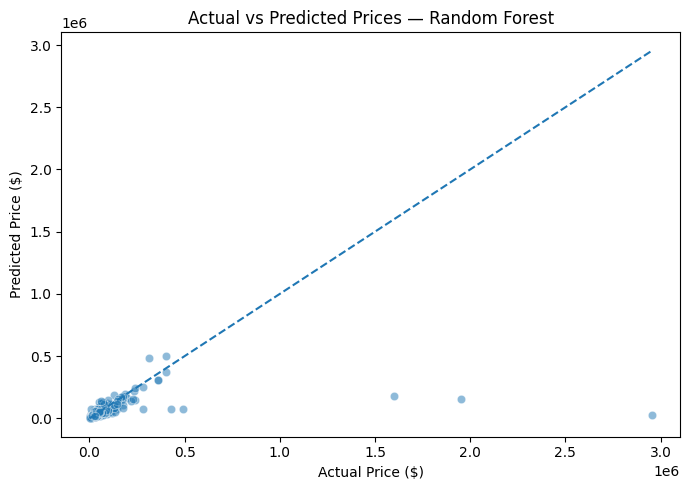

In [22]:
# Compare actual and predicted prices
results = pd.DataFrame({
    "actual_price": y_test,
    "predicted_price": rf_preds
})

results["absolute_error"] = (
    results["actual_price"] - results["predicted_price"]
).abs()

results["percentage_error"] = (
    results["absolute_error"] / results["actual_price"]
) * 100

# Largest prediction errors
display(
    results.sort_values("absolute_error", ascending=False).head(10)
)

# Actual vs predicted plot
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=results,
    x="actual_price",
    y="predicted_price",
    alpha=0.5
)

max_price = max(results["actual_price"].max(), results["predicted_price"].max())
plt.plot([0, max_price], [0, max_price], linestyle="--")
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Prices — Random Forest")
plt.tight_layout()
plt.show()

## 21. Log-Transformed Target Modeling

Train a Random Forest using the natural logarithm of the target price. Transform predictions back to dollars before evaluating them so results are comparable with the original-price model.

Compare MAE, RMSE, and R² on the same test set.

In [23]:
# Transform training target only
y_train_log = np.log1p(y_train)

# Build the pipeline
rf_log_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train on log-price
rf_log_model.fit(X_train, y_train_log)

# Predict and convert back to dollars
log_preds = rf_log_model.predict(X_test)
rf_log_preds = np.expm1(log_preds)

# Evaluate in original dollar units
log_mae = mean_absolute_error(y_test, rf_log_preds)
log_rmse = np.sqrt(mean_squared_error(y_test, rf_log_preds))
log_r2 = r2_score(y_test, rf_log_preds)

print("Random Forest — Log Target")
print(f"MAE:  ${log_mae:,.2f}")
print(f"RMSE: ${log_rmse:,.2f}")
print(f"R²:    {log_r2:.4f}")

print("\nModel Comparison")
print(f"Original target MAE: ${rf_mae:,.2f}")
print(f"Log target MAE:      ${log_mae:,.2f}")

Random Forest — Log Target
MAE:  $20,332.06
RMSE: $135,367.61
R²:    0.1035

Model Comparison
Original target MAE: $20,037.62
Log target MAE:      $20,332.06


## 22. Gradient Boosting Regression

Train a HistGradientBoosting-style alternative? Instead, use scikit-learn's `GradientBoostingRegressor` with the existing preprocessing pipeline to model nonlinear relationships. Evaluate it using the same held-out test set and metrics for a fair comparison.

In [24]:
from sklearn.ensemble import GradientBoostingRegressor

gbr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

# Train
gbr_model.fit(X_train, y_train)

# Predict
gbr_preds = gbr_model.predict(X_test)

# Evaluate
gbr_mae = mean_absolute_error(y_test, gbr_preds)
gbr_rmse = np.sqrt(mean_squared_error(y_test, gbr_preds))
gbr_r2 = r2_score(y_test, gbr_preds)

print("Gradient Boosting Performance")
print(f"MAE:  ${gbr_mae:,.2f}")
print(f"RMSE: ${gbr_rmse:,.2f}")
print(f"R²:    {gbr_r2:.4f}")

print("\nModel Comparison")
print(f"Baseline MAE:          ${baseline_mae:,.2f}")
print(f"Random Forest MAE:     ${rf_mae:,.2f}")
print(f"Gradient Boosting MAE: ${gbr_mae:,.2f}")

Gradient Boosting Performance
MAE:  $23,205.11
RMSE: $135,938.96
R²:    0.0959

Model Comparison
Baseline MAE:          $32,865.97
Random Forest MAE:     $20,037.62
Gradient Boosting MAE: $23,205.11


## 23. Data Quality and Category Frequency Review

Investigate the unusually priced Maserati listing and identify brands with very few records. Do not remove records automatically; use the findings to decide whether data correction, feature grouping, or model changes are justified.

In [25]:
# Inspect the suspicious listing
display(
    df_clean.loc[
        (df_clean["brand"] == "Maserati") &
        (df_clean["model"] == "Quattroporte Base"),
        ["brand", "model", "model_year", "milage", "price"]
    ]
)

# Brand frequency analysis
brand_counts = df_clean["brand"].value_counts()

print("Brands with 5 or fewer listings:")
display(brand_counts[brand_counts <= 5])

print("\nNumber of brands:", brand_counts.size)
print("Brands with 5 or fewer listings:", (brand_counts <= 5).sum())

# Check the target range for these rare brands
rare_brands = brand_counts[brand_counts <= 5].index

display(
    df_clean[df_clean["brand"].isin(rare_brands)]
    [["brand", "model", "model_year", "price"]]
    .sort_values("price", ascending=False)
    .head(20)
)

,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000.0,2954083.0
1143,Maserati,Quattroporte Base,2006,61840.0,16500.0
2355,Maserati,Quattroporte Base,2006,51000.0,18000.0


Brands with 5 or fewer listings:


brand
Saturn      5
FIAT        5
Lotus       4
Lucid       3
Mercury     3
Karma       2
Saab        2
Bugatti     1
Polestar    1
Plymouth    1
smart       1
Maybach     1
Suzuki      1
Name: count, dtype: int64


Number of brands: 57
Brands with 5 or fewer listings: 13


,brand,model,model_year,price
229,Bugatti,Veyron 16.4 Grand Sport,2011,1950995.0
44,Lucid,Air Grand Touring,2022,119999.0
68,Lucid,Air Grand Touring,2022,99000.0
129,Lucid,Air Pure,2023,86900.0
537,Lotus,Evora 400 Base,2017,69250.0
3114,Maybach,Type 57 Base,2004,64250.0
1554,Karma,Revero Base,2018,55500.0
2383,Lotus,Evora Base,2010,55000.0
3487,Lotus,Evora 2+2,2011,51000.0
719,Karma,Revero Base,2018,51000.0


## 24. Flag Suspicious Price Records

Flag potentially anomalous listings for further investigation using domain context and comparable records. A flagged record is not automatically removed; all exclusions must have a defensible reason.

Rare brands are retained because low frequency alone does not imply incorrect data.

In [26]:
# Flag the suspicious Maserati listing
suspicious_mask = (
    (df_clean["brand"] == "Maserati") &
    (df_clean["model"] == "Quattroporte Base") &
    (df_clean["model_year"] == 2005) &
    (df_clean["price"] > 1_000_000)
)

print("Potentially suspicious records:", suspicious_mask.sum())

display(
    df_clean.loc[
        suspicious_mask,
        ["brand", "model", "model_year", "milage", "price"]
    ]
)

Potentially suspicious records: 1


,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000.0,2954083.0


## 25. Sensitivity Analysis for a Suspicious Record

Compare the Random Forest model trained with the flagged record against a model trained without it. Use the same test set for both comparisons to measure sensitivity to the suspected anomaly.

The original dataset remains unchanged. The comparison is diagnostic, not proof that the record is incorrect.

In [27]:
# Reuse the original train/test split and remove the flagged
# record from training data only for this diagnostic comparison.
train_suspicious_mask = suspicious_mask.loc[X_train.index]

X_train_filtered = X_train.loc[~train_suspicious_mask]
y_train_filtered = y_train.loc[~train_suspicious_mask]

# Train a comparison model
rf_filtered_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_filtered_model.fit(X_train_filtered, y_train_filtered)

# Evaluate on the same test set
filtered_preds = rf_filtered_model.predict(X_test)

print("Original RF MAE:", round(rf_mae, 2))
print(
    "Filtered-training RF MAE:",
    round(mean_absolute_error(y_test, filtered_preds), 2)
)

print("Original RF RMSE:", round(rf_rmse, 2))
print(
    "Filtered-training RF RMSE:",
    round(np.sqrt(mean_squared_error(y_test, filtered_preds)), 2)
)

print("Original RF R²:", round(rf_r2, 4))
print("Filtered-training RF R²:", round(r2_score(y_test, filtered_preds), 4))
print("Training rows before:", len(X_train))
print("Training rows after:", len(X_train_filtered))

Original RF MAE: 20037.62
Filtered-training RF MAE: 20037.62
Original RF RMSE: 134030.45
Filtered-training RF RMSE: 134030.45
Original RF R²: 0.1211
Filtered-training RF R²: 0.1211
Training rows before: 3207
Training rows after: 3207


## 26. Verify Suspicious Record Split

Check whether the flagged record belongs to the training or test set. This determines whether the previous sensitivity comparison actually excluded it from training.

In [28]:
suspicious_indices = df_clean.index[suspicious_mask]

print("Flagged record index:", suspicious_indices.tolist())
print("In training set:", suspicious_indices.intersection(X_train.index).tolist())
print("In test set:", suspicious_indices.intersection(X_test.index).tolist())

Flagged record index: [693]
In training set: []
In test set: [693]




## 27. Evaluate Model Performance by Price Range

Evaluate the Random Forest model across different actual price ranges. This helps identify whether the model performs differently for budget, mid-range, and luxury vehicles.

In [29]:

evaluation = results.copy()

evaluation["price_range"] = pd.cut(
    evaluation["actual_price"],
    bins=[0, 20000, 50000, 100000, float("inf")],
    labels=["Under $20K", "$20K–$50K", "$50K–$100K", "Above $100K"]
)

range_metrics = evaluation.groupby(
    "price_range", observed=False
).agg(
    cars=("actual_price", "count"),
    MAE=("absolute_error", "mean"),
    median_actual_price=("actual_price", "median")
).round(2)

display(range_metrics)


,cars,MAE,median_actual_price
price_range,,,
Under $20K,248,5908.54,12500.0
$20K–$50K,374,8827.71,33000.0
$50K–$100K,132,18568.15,67850.0
Above $100K,48,184422.78,168500.0



## 28. Analyze the Impact of the Extreme Test Record

Calculate the model's overall MAE with and without the flagged test record for diagnostic purposes. Keep the original test set unchanged for the primary evaluation.

In [30]:

flagged_test_indices = suspicious_indices.intersection(y_test.index)

print("Flagged test indices:", flagged_test_indices.tolist())

mae_with_record = mean_absolute_error(y_test, rf_preds)

keep_mask = ~y_test.index.isin(flagged_test_indices)
mae_without_record = mean_absolute_error(
    y_test.iloc[keep_mask],
    rf_preds[keep_mask]
)

print(f"MAE with all test records: ${mae_with_record:,.2f}")
print(f"Diagnostic MAE without flagged record: ${mae_without_record:,.2f}")


Flagged test indices: [693]
MAE with all test records: $20,037.62
Diagnostic MAE without flagged record: $16,406.72



## 29. Random Forest Hyperparameter Tuning

Use 3-fold cross-validation on the training data to find better Random Forest hyperparameters. The test set will remain untouched during tuning.

In [31]:

from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
])

param_distributions = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [None, 15, 25, 35],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0, "sqrt"],
}

cv = KFold(n_splits=3, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best CV MAE: ${-search.best_score_:,.2f}")


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 25}
Best CV MAE: $12,955.33


l

## 30. Evaluate Tuned Random Forest

Fit the best estimator selected through cross-validation and evaluate it on the held-out test set. Compare it with the original Random Forest using MAE, RMSE, and R².

### Markdown cell

## 30. Evaluate Tuned Random Forest

Fit the best estimator selected through cross-validation and evaluate it on the held-out test set. Compare it with the original Random Forest using MAE, RMSE, and R².

In [32]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_rf_model = search.best_estimator_
tuned_preds = best_rf_model.predict(X_test)

tuned_metrics = {
    "Model": "Tuned Random Forest",
    "MAE": mean_absolute_error(y_test, tuned_preds),
    "RMSE": np.sqrt(mean_squared_error(y_test, tuned_preds)),
    "R2": r2_score(y_test, tuned_preds),
}

original_metrics = {
    "Model": "Original Random Forest",
    "MAE": mean_absolute_error(y_test, rf_preds),
    "RMSE": np.sqrt(mean_squared_error(y_test, rf_preds)),
    "R2": r2_score(y_test, rf_preds),
}

display(pd.DataFrame([original_metrics, tuned_metrics]).round(4))


,Model,MAE,RMSE,R2
0,Original Random Forest,20037.6166,134030.4462,0.1211
1,Tuned Random Forest,19602.7574,134827.1941,0.1106


### Markdown cell

## 31. Extra Trees Regressor

Train an Extra Trees model using the same preprocessing pipeline and train/test split. Compare its performance with the existing Random Forest.

Extra Trees uses more randomized tree splits, which may generalize differently on this dataset.

In [33]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

extra_trees_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees_model.fit(X_train, y_train)
extra_preds = extra_trees_model.predict(X_test)

extra_metrics = {
    "Model": "Extra Trees",
    "MAE": mean_absolute_error(y_test, extra_preds),
    "RMSE": np.sqrt(mean_squared_error(y_test, extra_preds)),
    "R2": r2_score(y_test, extra_preds)
}

display(pd.DataFrame([
    original_metrics,
    tuned_metrics,
    extra_metrics
]).round(4))


,Model,MAE,RMSE,R2
0,Original Random Forest,20037.6166,134030.4462,0.1211
1,Tuned Random Forest,19602.7574,134827.1941,0.1106
2,Extra Trees,19657.4219,135509.8376,0.1016



## 32. Final Model Comparison

Compare the three candidate models using MAE, RMSE, and R². MAE measures typical absolute prediction error, RMSE penalizes large errors more heavily, and R² measures variance explained by the model.

No single model wins every metric. Consider the intended use case before selecting the final model.

In [34]:

comparison = pd.DataFrame([
    original_metrics,
    tuned_metrics,
    extra_metrics
]).sort_values("MAE")

display(comparison.round(2))

print("Lowest MAE:", comparison.iloc[0]["Model"])
print("Lowest RMSE:", comparison.loc[comparison["RMSE"].idxmin(), "Model"])
print("Highest R2:", comparison.loc[comparison["R2"].idxmax(), "Model"])


,Model,MAE,RMSE,R2
1,Tuned Random Forest,19602.76,134827.19,0.11
2,Extra Trees,19657.42,135509.84,0.10
0,Original Random Forest,20037.62,134030.45,0.12


Lowest MAE: Tuned Random Forest
Lowest RMSE: Original Random Forest
Highest R2: Original Random Forest




## 33. Feature Importance

Extract feature importance from the trained Random Forest pipeline. One-hot encoding expands categorical columns into multiple features, so this analysis shows which encoded features contribute most to the model's predictions.

Feature importance indicates predictive usefulness, not causation.

,feature,importance
2,num__milage,0.350697
27,cat__brand_Lamborghini,0.130224
48,cat__brand_Rolls-Royce,0.119960
15,cat__brand_Ferrari,0.044209
45,cat__brand_Porsche,0.038549
309,cat__model_Aventador SVJ Base,0.036860
8,cat__brand_Bentley,0.026551
0,num__model_year,0.024530
1,num__vehicle_age,0.023828
2762,cat__transmission_7-Speed Automatic with Auto-...,0.014777


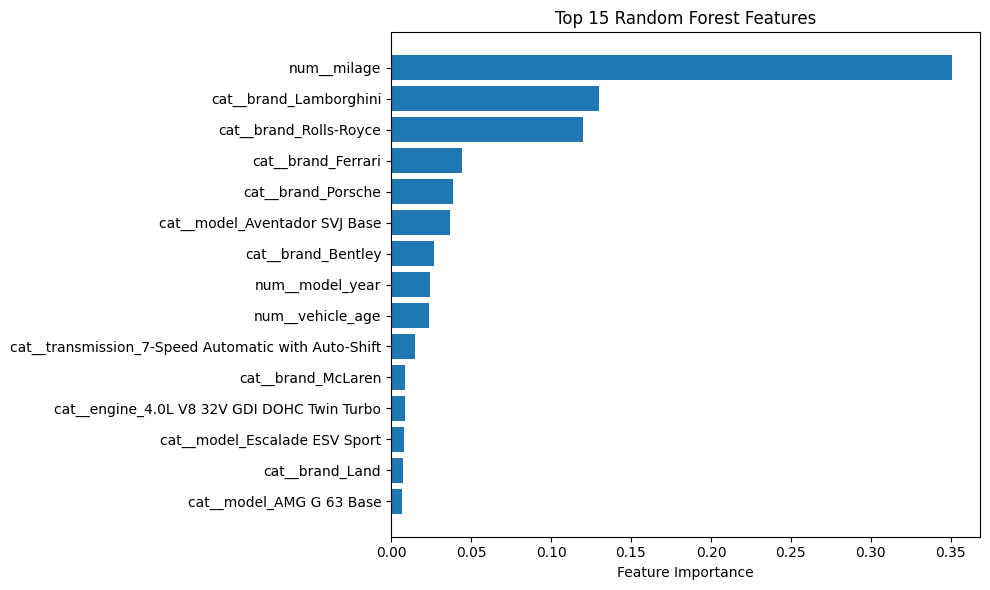

In [35]:

fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_rf = rf_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": fitted_rf.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.head(20))

import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Random Forest Features")
plt.tight_layout()
plt.show()


### Markdown cell

## 34. Actual vs Predicted Price

Visualize actual and predicted prices from the original Random Forest model. The diagonal line represents perfect predictions. Large deviations indicate prediction errors, especially for expensive vehicles.

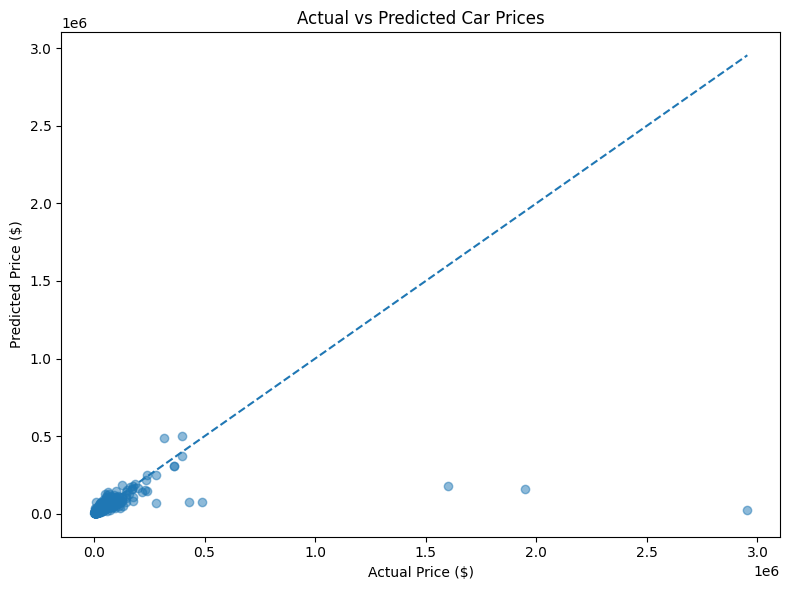

In [36]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_preds, alpha=0.5)

max_price = max(y_test.max(), rf_preds.max())
plt.plot([0, max_price], [0, max_price], linestyle="--")

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Car Prices")
plt.tight_layout()
plt.show()


### Markdown cell

## 35. Model Limitations and Key Findings

- The original Random Forest achieved MAE of approximately $20,038 and R² of 0.121 on the test set.
- Predictions for extremely expensive vehicles are substantially lower than actual prices.
- The dataset contains a potentially suspicious Maserati price record that has not been independently verified.
- Mileage is the most important feature in the current model, followed by indicators for luxury brands.
- Rare brands and models have limited training examples, which may reduce generalization.
- Model comparisons used the same test set repeatedly; therefore, reported test metrics are exploratory rather than an untouched final evaluation.

These limitations should be considered before using the model for real-world pricing decisions.

## Section 36 — Save the Model Pipeline
We'll save the complete original Random Forest pipeline, including preprocessing, so it can later be reused for predictions.

In [37]:

from pathlib import Path
import joblib

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "used_car_price_model.joblib"

joblib.dump(rf_model, MODEL_PATH)

print("Model saved to:", MODEL_PATH)
print("File exists:", MODEL_PATH.exists())


Model saved to: D:\SAURABH\FDE_Course\Projects\Used_Car_Price_Prediction\models\used_car_price_model.joblib
File exists: True


### Markdown cell

## 37. Load Model and Test Prediction

Load the saved model pipeline and generate a prediction using one record from the test dataset. This verifies that the saved artifact includes both preprocessing and the trained model.

In [38]:

import joblib

loaded_model = joblib.load(MODEL_PATH)

sample_car = X_test.iloc[[0]]
actual_price = y_test.loc[sample_car.index[0]]
predicted_price = loaded_model.predict(sample_car)[0]

print(f"Actual price:    ${actual_price:,.2f}")
print(f"Predicted price: ${predicted_price:,.2f}")
print(f"Absolute error:  ${abs(actual_price - predicted_price):,.2f}")


Actual price:    $28,000.00
Predicted price: $36,524.11
Absolute error:  $8,524.11


In [41]:

print("Accident values:")
print(sorted(df_clean["accident"].dropna().unique()))

print("\nClean title values:")
print(sorted(df_clean["clean_title"].dropna().unique()))


Accident values:
['At least 1 accident or damage reported', 'None reported']

Clean title values:
['Yes']
